# 高维数据与维度灾难
所有实验使用真实白血病数据。先填写预测，再运行。

In [2]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image
HERE=Path.cwd().resolve()
REPO=next((p for p in [HERE,*HERE.parents] if (p/"assignments/hw03/resources/scripts/experiments.py").exists()),None)
if REPO is None: raise RuntimeError("请在课程仓库内运行HW03 Notebook")
BASE=REPO/"assignments/hw03/resources"
sys.path.insert(0,str(BASE/"scripts"))
import experiments as lab
OUT=HERE/"student-results"
OUT.mkdir(exist_ok=True)

## T1 读取真实数据

In [5]:
df,X,names=lab.load_real()
print("n,p",X.shape,"p/n",X.shape[1]/X.shape[0])
display(df.groupby(["original_split","diagnosis"]).size().rename("n").to_frame())
display(df.iloc[:3,:10])

n,p (72, 7129) p/n 99.01388888888889


n
original_split diagnosis    
test           ALL        20
               AML        14
train          ALL        27
               AML        11

,sample_id,original_split,diagnosis,AFFX-BioB-5_at,AFFX-BioB-M_at,AFFX-BioB-3_at,AFFX-BioC-5_at,AFFX-BioC-3_at,AFFX-BioDn-5_at,AFFX-BioDn-3_at
0,G001,train,ALL,-214,-153,-58,88,-295,-558,199
1,G002,train,ALL,-139,-73,-1,283,-264,-400,-330
2,G003,train,ALL,-76,-49,-307,309,-376,-650,33


## T2 实验A 距离
先写预测。诊断只在图中事后着色。

,42,7,2026
0,X51730_at,M60052_at,U26727_at
1,U13616_at,HG2600-HT2696_at,M34516_r_at
2,X97261_at,X04741_at,U59831_rna1_s_at


,seed,p,mean,sd,cv,near_median,far_median,gap_median,r_median,zero_nearest
0,42,2,1.268799,1.564125,1.232761,0.067518,7.903008,7.860022,115.451967,0
1,42,3,1.810146,1.675672,0.925711,0.234539,8.763866,8.482727,35.998344,0
2,42,10,4.215053,1.585882,0.376243,1.797615,9.655803,7.559482,4.318717,0
3,42,100,13.916946,3.022502,0.217181,9.669579,21.461561,12.011417,1.199352,0
4,42,1000,44.181567,8.726863,0.197523,33.067257,66.515369,34.236792,1.048856,0
5,42,7129,118.196488,22.099935,0.186976,87.931134,174.900278,87.138000,0.966904,0


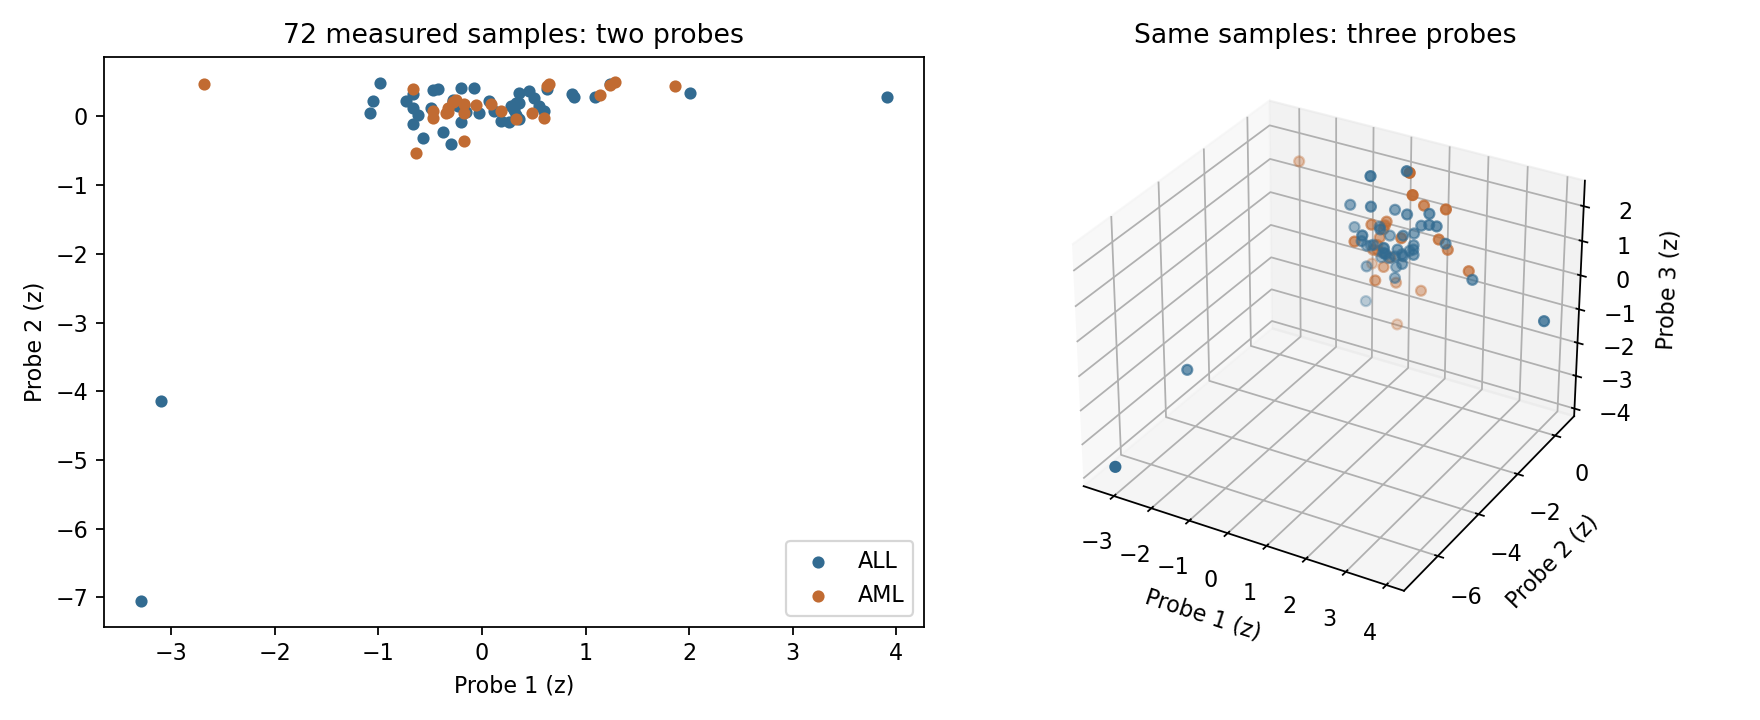

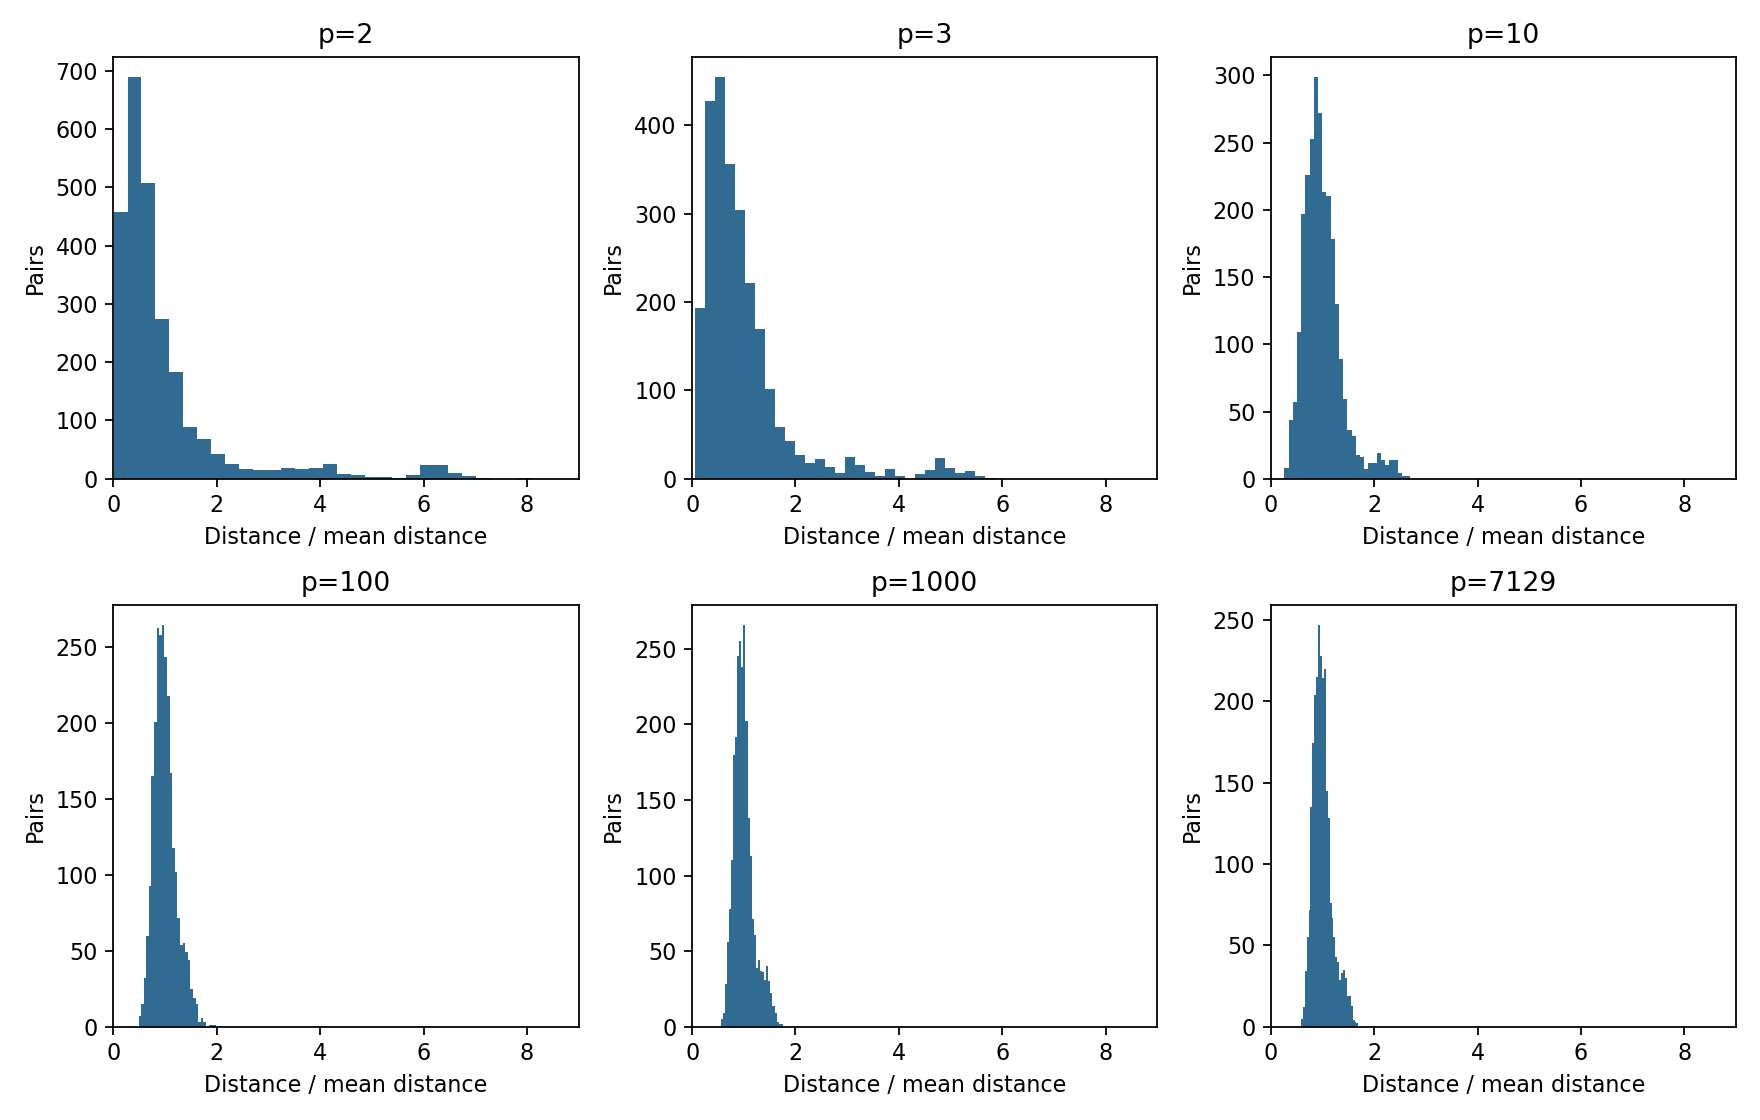

In [3]:
a=lab.experiment_a(OUT)
display(pd.read_csv(OUT/"A-probe-orders.csv").head(3))
display(a[a.seed.eq(42)])
display(Image(filename=str(OUT/"A-scatter-2D-3D.png")))
display(Image(filename=str(OUT/"A-distance-distributions.png")))

## T3 近远邻与选列

In [4]:
near=pd.read_csv(OUT/"A-neighbors-seed42.csv")
display(near[near.sample_id.eq("G001") & near.p.isin([2,7129])])
display(a[["seed","p","cv","r_median","gap_median"]])

,sample_id,p,near,far,R
0,G001,2,0.049192,7.954082,160.695864
360,G001,7129,93.695760,156.146171,0.666523


,seed,p,cv,r_median,gap_median
0,42,2,1.232761,115.451967,7.860022
1,42,3,0.925711,35.998344,8.482727
2,42,10,0.376243,4.318717,7.559482
3,42,100,0.217181,1.199352,12.011417
4,42,1000,0.197523,1.048856,34.236792
5,42,7129,0.186976,0.966904,87.138000
6,7,2,0.614496,23.676032,4.234162
7,7,3,0.539419,10.198094,4.667459
8,7,10,0.301309,2.400987,5.317424
9,7,100,0.214420,1.286433,13.079189


## T4 实验B 先看训练
先记录训练分数能支持什么。

In [5]:
b,cv=lab.experiment_b(OUT)
display(b[["p","train_ba"]])

,p,train_ba
0,2,1.0
1,10,1.0
2,100,1.0
3,1000,1.0
4,7129,1.0


记录判断后再看测试。

,p,train_ba,test_ba,ALL_correct,AML_correct
0,2,1.0,0.496429,17,2
1,10,1.0,0.578571,16,5
2,100,1.0,0.653571,19,5
3,1000,1.0,0.725000,19,7
4,7129,1.0,0.760714,19,8


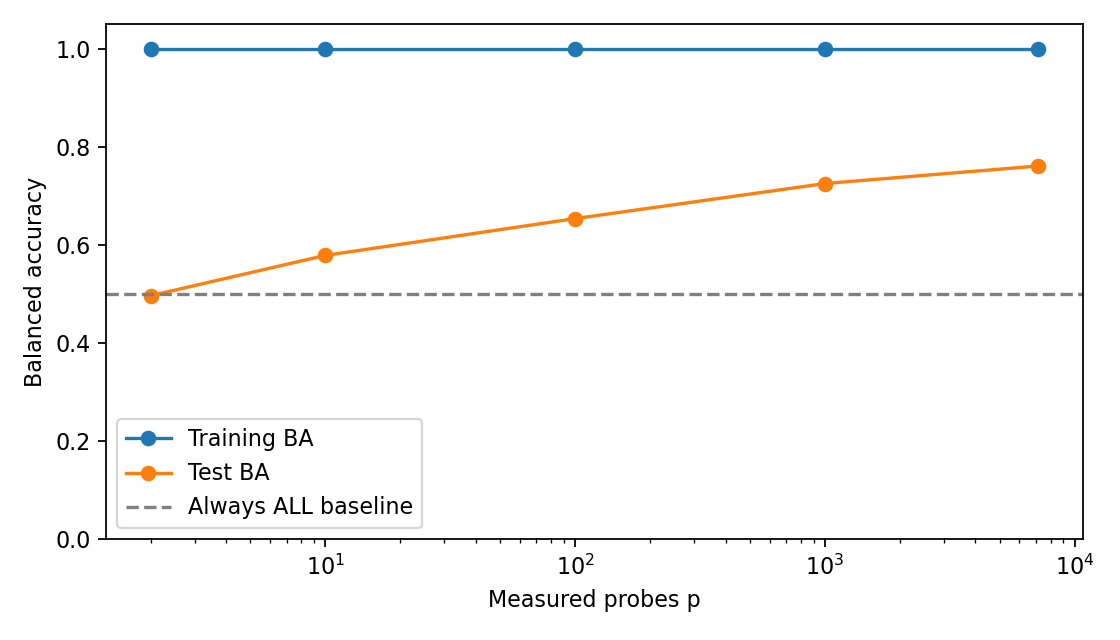

恒预测ALL的BA基线0.5


In [6]:
display(b)
display(Image(filename=str(OUT/"B-generalization.png")))
print("恒预测ALL的BA基线0.5")

## T5 退出卡
在工作单完成理论计算、流程修复与结论。

## H1 验证与筛选稳定性

In [7]:
display(cv.groupby("method").validation_ba.agg(["mean","min","max","std"]))
display(cv)
stability=pd.read_csv(OUT/"B-selection-stability.csv")
display(stability.jaccard.agg(["median","min","max"]))
import importlib.metadata
print({n:importlib.metadata.version(n) for n in ["numpy","pandas","scipy","scikit-learn","matplotlib"]})

,mean,min,max,std
method,,,,
all7129,0.844136,0.694444,1.0,0.106858
select20,0.885802,0.750000,1.0,0.083269


,repeat,fold,method,train_n,validation_n,train_ba,validation_ba
0,1,1,all7129,25,13,1.0,0.819444
1,1,1,select20,25,13,1.0,0.875000
2,1,2,all7129,25,13,1.0,0.875000
3,1,2,select20,25,13,1.0,0.944444
4,1,3,all7129,26,12,1.0,0.833333
5,1,3,select20,26,12,1.0,1.000000
6,2,1,all7129,25,13,1.0,0.750000
7,2,1,select20,25,13,1.0,0.750000
8,2,2,all7129,25,13,1.0,0.875000
9,2,2,select20,25,13,1.0,0.819444


median    0.270161
min       0.142857
max       0.428571
Name: jaccard, dtype: float64

{'numpy': '2.3.5', 'pandas': '2.3.3', 'scipy': '1.17.0', 'scikit-learn': '1.8.0', 'matplotlib': '3.10.8'}


## 我的解释

### 主张
我部分赞同“特征越多，模型一定越好”，主要原因是模型后续表现有一定提升。这份白血病微阵列数据有 72 份样本、7129 个探针，p/n≈99.0139；探针数量不等于独立有效信息量，相关探针、噪声和有效信号都可能随特征数增加。模型表现应由规范的验证结果判断。

### 距离证据
实验 A 对 72 份样本逐探针做 z-score 标准化，再计算欧氏距离。seed=42 时，p 从 2 增至 7129，距离 CV（样本对距离标准差/均值）由 1.232761 降至 0.186976，逐样本近远邻相对差异 R=(far−near)/near 的中位数由 115.451967 降至 0.966904。G001 的 R 也由 160.695864 降至 0.666523。这表示距离相对于自身尺度更集中、近远邻的相对区分减弱，不表示所有距离相等；绝对差异 gap 的中位数反而由 7.860022 增至 87.138000。不同随机顺序下总体趋势相似，但并非每一步都单调下降。

### 泛化证据
实验 B 按 original_split 固定使用 38 份训练样本和 34 份测试样本，StandardScaler 只在训练集拟合，再用 1 近邻分类。所有 p 下训练 BA 都为 1.0，因为训练样本预测自身时，距离为 0 的自身就是最近邻，不能据此判断新患者表现。p=2、10、100、1000、7129 时，测试 BA 分别为 0.496429、0.578571、0.653571、0.725000、0.760714。BA 是 ALL 与 AML 召回率的平均值；全特征时为 (19/20+8/14)/2=0.760714，高于恒预测 ALL 的 0.5 基线，但 AML 仍只判对 8/14。

### 验证与特征稳定性
仅在 38 份训练样本内进行 3 折、重复 3 次的分层交叉验证，全部 7129 个探针的验证 BA 均值为 0.844136、标准差为 0.106858；折内筛选 20 个探针后均值为 0.885802、标准差为 0.083269。9 次配对比较中 5 次提高、2 次降低、2 次持平，因此不能说筛选每次都更好。所选特征集合的 Jaccard 中位数仅为 0.270161，说明预测表现较好也不等于探针名单稳定，更不能直接把它们认定为确定的生物标志物。重复交叉验证复用了样本，9 次结果不是 9 个独立研究。

### 推理与边界
距离相对集中与测试表现改善可以同时出现：增加真实探针时，维度和特征内容同时改变，新增信号可能抵消冗余或噪声的影响。当前结果支持“需要验证，不能只看特征数或训练成绩”，不能证明更多特征普遍更好或更差，也不能证明因果机制、临床效用或对新中心患者的泛化。教学编号不足以核验患者独立性，批次等混杂信息也不充分。若在同一验证结果上反复调整特征数或方法，需要进一步用嵌套验证或独立队列评估。

折内特征筛选已用于本实验；PCA 可作为后续压缩相关特征的方案，但本次没有运行 PCA，它保留最大方差方向，不保证保留最有分类价值的低方差信号。若使用，应只在训练部分拟合，并在验证流程内选择维数，最后在锁定的独立患者队列中检验。
